# 07 · Time Series Forecasting with Neural Networks

Module 06 taught how a recurrent network remembers and showed a first forecast on a synthetic signal. Real forecasting is harsher: the data is messy, a one-line baseline is surprisingly hard to beat, and a gradient-boosting model that trains in two seconds is waiting for you at the finish line. This module puts the neural models through that test on **two real-style problems with opposite winners**, then asks whether a model that was *never trained on your data* can do as well.

> The broad, method-by-method version of this comparison (SARIMA, Prophet, Keras and all) is the [Python 1001 time series module](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/). This notebook copies its two problems and its data loading, drops what is not neural, and goes deeper on the neural side, so the numbers are comparable (differences are explained where they appear).

| Section | Idea | Experiment |
|---|---|---|
| 1 | how to frame and evaluate neural forecasts | direct multi-horizon forecasts from rolling origins |
| 2-3 | baselines to beat | seasonal naive and XGBoost (extreme gradient boosting) on hourly bike-sharing demand |
| 4 | recurrent and attention networks on real data | a GRU (gated recurrent unit), an LSTM (long short-term memory) and a patch Transformer in PyTorch |
| 5-6 | a second problem where memory matters | river flow driven by rain: baselines, then encoder-decoder GRU and LSTM and a patch Transformer |
| 7 | zero-shot foundation model | TimesFM 3 (a pre-trained Transformer) forecasts both problems without any training |
| 8 | uncertainty | quantile (pinball) loss: a network that predicts a band, not a line, and how its band compares with the foundation model's |
| 9 | decision guide | when each neural model is worth its cost |

**Contents:** 1. Framing and evaluation, 2. Problem 1 data, 3. Baselines, 4. Neural networks on problem 1, 5. Problem 2 data and baselines, 6. Neural networks on problem 2, 7. Zero-shot foundation model, 8. Probabilistic forecasting, 9. Decision guide, Key takeaways, Exercises, References.

**Builds on**

| Module | What it gave you |
|---|---|
| [01 · The neuron](https://neural-networks.academy.forwardforecasting.eu/01-the-neuron/) and [02 · Backprop](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) | layers, loss, gradient descent |
| [03 · Training well](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | normalisation, early stopping, Adam |
| [06 · Recurrent networks](https://neural-networks.academy.forwardforecasting.eu/06-recurrent-networks/) | the GRU/LSTM loop, hidden state, direct multi-horizon forecasts, the seasonal-naive baseline. Not repeated here. |
| [09 · The Transformer](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | self-attention and encoder blocks, used in section 4 on patches of a series |

Everything is PyTorch and runs on a CPU. The two datasets are small; the one download that is not small is the 1.3 GB foundation model, cached after the first run, and its forecasts are cached too, so a second run skips that computation. In a clean 2-CPU environment the whole notebook took about 3 minutes with the forecasts already cached; the first time, computing them adds a few more minutes.

**Where this toy differs from real systems:** real forecasting services train on thousands of series and years of data, tune each model, and re-train on a schedule. Here every network is small, trained for a few minutes on one or two datasets, so read the *ranking and the reasons*, not the third digit.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks/07_time_series_forecasting.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 3 minutes, with a peak memory of about 1.6 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [1]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'xgboost': 'xgboost',
    'timesfm3': 'timesfm @ git+https://github.com/google-research/timesfm.git@e51928e27119cb17bebc005be2696b75e0a9e688',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

Installing: timesfm @ git+https://github.com/google-research/timesfm.git@e51928e27119cb17bebc005be2696b75e0a9e688


Environment: Python 3.12.3 | local | CPUs: 32


## 1. Framing and evaluation

**Direct multi-horizon forecasting.** At each forecast origin (a moment when we must issue a forecast, for example every midnight) the model sees the past and outputs all $H$ future values at once, rather than feeding its own predictions back (the recursive way that module 06 showed compounds errors).

**Known future inputs.** Some inputs are known when the forecast is issued: the calendar, a weather or rain forecast. They are given to the model as a second input next to the history. Neural networks handle this naturally: a recurrent encoder reads the history, and the known future is concatenated (problem 1) or fed step by step to a decoder (problem 2).

**Honest evaluation.**
- Split by **time**, never at random: train on the past, test on the future.
- Forecast from many **rolling origins** in the test period, as the model would be used.
- Always report a **baseline**: a network that cannot beat seasonal naive is not useful.
- Report an error in the units people care about (bikes per hour, flow units) and, where it matters, the error on the **rare large events**.

Notation used below: $L$ is the number of past hours given to the model, $H$ the number of hours to forecast, MAE (mean absolute error) the average of $|\text{forecast} - \text{actual}|$, and RMSE (root mean squared error) the square root of the average squared error, which punishes large misses more.

## 2. Problem 1: hourly bike-sharing demand

Two years (2011-2012) of hourly rentals from Washington D.C.'s Capital Bikeshare, with the weather and the calendar: the UCI (University of California Irvine) *Bike Sharing* dataset ([Fanaee-T and Gama, 2013](https://doi.org/10.1007/s13748-013-0040-3); [dataset page](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), licence CC BY 4.0, a licence that only asks for credit), downloaded from [OpenML](https://www.openml.org/d/42712) and cached by scikit-learn. The copy on OpenML drops the date column; the rows are in time order, so the timestamps are rebuilt from the year, month, weekday and hour fields, and 165 missing hours (no rentals recorded) are filled. This is the same loading code as the Python 1001 module.

**Task:** every midnight, forecast the 24 hourly counts of the coming day. Train on January 2011 to September 2012, test on the 92 days of October to December 2012. We model $\log(1 + \text{count})$ so errors at night and at rush hour count proportionally, and score in bikes per hour.

(17544, 11) 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


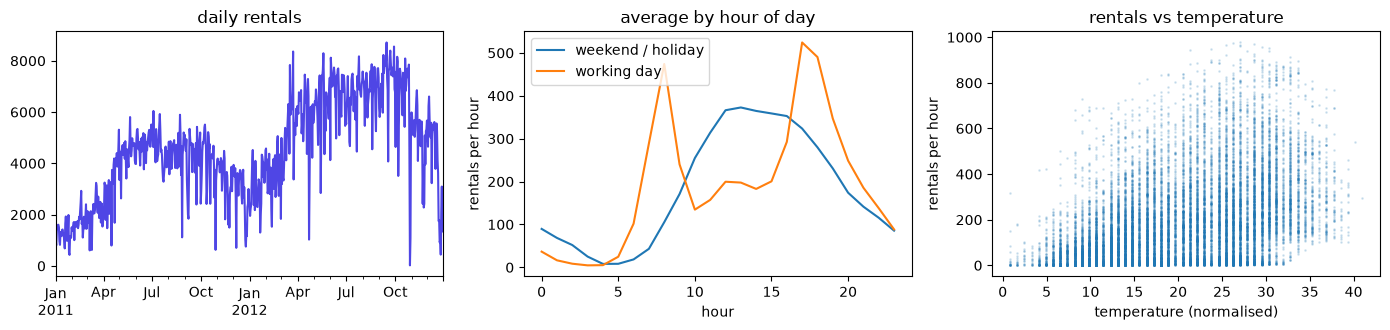

In [2]:
import os, time, warnings, logging
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import fetch_openml

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(2)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

try:
    raw = fetch_openml(data_id=42712, as_frame=True, parser="auto").frame
except TypeError:      # some pandas and scikit-learn version pairs break the fast ARFF parser; the pure-Python one is slower but always works
    raw = fetch_openml(data_id=42712, as_frame=True, parser="liac-arff").frame
# a new day starts whenever the hour goes back down or the weekday changes
day, days, prev_h, prev_wd = 0, [], None, None
for h, wd in zip(raw["hour"].astype(int), raw["weekday"].astype(str)):
    if prev_h is not None and (h <= prev_h or wd != prev_wd):
        day += 1
    days.append(day); prev_h, prev_wd = h, wd
raw.index = pd.Timestamp("2011-01-01") + pd.to_timedelta(days, "D") + pd.to_timedelta(raw["hour"].astype(int), "h")
assert (raw.index.dayofweek == (raw["weekday"].astype(int) + 6) % 7).all()     # rebuilt dates match the weekdays

WEATHER = ["temp", "feel_temp", "humidity", "windspeed"]
bike = raw.reindex(pd.date_range(raw.index.min(), raw.index.max(), freq="h"))
bike["count"] = bike["count"].fillna(0)
for c in WEATHER + ["weather", "holiday", "workingday"]:
    bike[c] = bike[c].ffill()
bike = pd.DataFrame({
    "count": bike["count"].astype(float),
    **{c: bike[c].astype(float) for c in WEATHER},
    "weather": bike["weather"].astype(str).astype("category").cat.codes,
    "holiday": bike["holiday"].astype(str).isin(["True", "1"]).astype(int),
    "workingday": bike["workingday"].astype(str).isin(["True", "1"]).astype(int),
}, index=bike.index)
bike["hour"], bike["dow"], bike["month"] = bike.index.hour, bike.index.dayofweek, bike.index.month
print(bike.shape, bike.index.min(), "->", bike.index.max())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
bike["count"].resample("D").sum().plot(ax=ax[0], title="daily rentals", color="#4f46e5"); ax[0].set_xlabel("")
for wd, g in bike.groupby("workingday"):
    g.groupby("hour")["count"].mean().plot(ax=ax[1], label="working day" if wd else "weekend / holiday")
ax[1].legend(); ax[1].set_title("average by hour of day"); ax[1].set_ylabel("rentals per hour")
ax[2].scatter(bike["temp"], bike["count"], s=1, alpha=.15); ax[2].set_xlabel("temperature (normalised)")
ax[2].set_ylabel("rentals per hour"); ax[2].set_title("rentals vs temperature")
plt.tight_layout(); plt.show()

In [3]:
bike["y"] = np.log1p(bike["count"])
TEST_START = pd.Timestamp("2012-10-01")
test_days = pd.date_range(TEST_START, bike.index.max().normalize(), freq="D")
y_true = bike.loc[bike.index >= TEST_START, "count"].to_numpy()

results, forecasts = {}, {}
def score(name, pred_log, seconds, params=None):
    pred = np.clip(np.expm1(np.asarray(pred_log)), 0, None)
    forecasts[name] = pred
    results[name] = {"MAE (bikes/h)": np.mean(np.abs(pred - y_true)),
                     "RMSE (bikes/h)": np.sqrt(np.mean((pred - y_true) ** 2)),
                     "seconds": seconds, "parameters": params}
    print(f"{name:<26} MAE {results[name]['MAE (bikes/h)']:6.1f}   RMSE {results[name]['RMSE (bikes/h)']:6.1f}   ({seconds:.0f} s)")
print(f"{len(test_days)} test days, {len(y_true):,} hours")

92 test days, 2,208 hours


## 3. The baselines to beat: seasonal naive and XGBoost

Two models that are not neural networks set the bar, and every network below has to be compared with both.

- **Seasonal naive**: tomorrow at 8:00 will look like the same day last week at 8:00. One line, no fitting. A network that loses to it is broken or useless.
- **XGBoost** ([Chen and Guestrin, 2016](https://arxiv.org/abs/1603.02754)): gradient-boosted decision trees on a table of features: calendar, weather and **lags known at midnight** (the same hour yesterday, two days ago, last week, and yesterday's average). One model predicts every hour of the day directly.

SARIMA (seasonal autoregressive integrated moving average), Prophet and the other classical methods are compared on this same problem in the [Python 1001 module](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/); on this data both lose to seasonal naive, which is why they are not repeated here.

In [4]:
t0 = time.perf_counter()
score("Seasonal naive (7 d)", bike["y"].shift(168).loc[bike.index >= TEST_START], time.perf_counter() - t0, 0)

import xgboost as xgb
feat = bike.copy()
feat["lag24"], feat["lag48"], feat["lag168"] = feat["y"].shift(24), feat["y"].shift(48), feat["y"].shift(168)
feat["prev_day_mean"] = feat["y"].shift(24).rolling(24).mean()     # ends at the forecast's midnight at the latest
feat["trend"] = np.arange(len(feat))
FEATURES = ["hour", "dow", "month", "workingday", "holiday", "weather", *WEATHER,
            "lag24", "lag48", "lag168", "prev_day_mean", "trend"]
tr_rows = feat.loc[feat.index < TEST_START].dropna()
te_rows = feat.loc[feat.index >= TEST_START]

t0 = time.perf_counter()
xgb_model = xgb.XGBRegressor(n_estimators=800, max_depth=7, learning_rate=0.03, subsample=0.8,
                             colsample_bytree=0.8, n_jobs=2, random_state=0)
xgb_model.fit(tr_rows[FEATURES], tr_rows["y"])
score("XGBoost", xgb_model.predict(te_rows[FEATURES]), time.perf_counter() - t0, "800 trees")

Seasonal naive (7 d)       MAE   75.9   RMSE  129.8   (0 s)


XGBoost                    MAE   44.6   RMSE   71.0   (1 s)


## 4. Neural networks on problem 1: GRU, LSTM and a patch Transformer

The sequence models get the raw history instead of hand-made lags: the last **7 days** (168 hours) of demand, weather and calendar, plus the weather and calendar of the **24 hours to forecast**, and output the 24 values at once. The calendar enters as sine and cosine of the hour and weekday, so that 23:00 and 00:00 are neighbours. Everything is normalised with training statistics only. Training uses every fourth hour of the training period as a forecast origin (about 3,600 examples); the last four weeks of training data are held out to stop training at the best epoch (early stopping, module 03).

Three architectures share one training loop and one interface `model(past, future_covariates)`:

- **GRU** and **LSTM** (module 06): a recurrent encoder reads the week; its final hidden state is concatenated with the next day's covariates and a small feed-forward head outputs the 24 values.
- **Patch Transformer**, the idea of PatchTST ([Nie et al., 2023](https://arxiv.org/abs/2211.14730)): cutting the series into **patches** (here one patch per day, 24 hours of all features) and treating each patch as one token. Attention then works over 7 tokens instead of 168 hours, which is far cheaper and was the key to making Transformers work for forecasting. The Transformer here is the encoder block of module 09 with learned positions.

In [5]:
SEQ_IN = ["y", "temp", "humidity", "windspeed", "workingday", "holiday"]
FUT_IN = ["temp", "humidity", "windspeed", "workingday", "holiday"]
L, H = 168, 24
arr = bike.assign(h_sin=np.sin(2 * np.pi * bike["hour"] / 24), h_cos=np.cos(2 * np.pi * bike["hour"] / 24),
                  d_sin=np.sin(2 * np.pi * bike["dow"] / 7), d_cos=np.cos(2 * np.pi * bike["dow"] / 7))
CAL = ["h_sin", "h_cos", "d_sin", "d_cos"]
past = arr[SEQ_IN + CAL].to_numpy(np.float32)
future = arr[FUT_IN + CAL].to_numpy(np.float32)
target = arr["y"].to_numpy(np.float32)
n_train_rows = arr.index.get_loc(TEST_START)
mu, sd = past[:n_train_rows].mean(0), past[:n_train_rows].std(0) + 1e-6
fmu, fsd = future[:n_train_rows].mean(0), future[:n_train_rows].std(0) + 1e-6
past_n, fut_n = (past - mu) / sd, (future - fmu) / fsd
y_mu, y_sd = mu[0], sd[0]

def make(origins):
    X = np.stack([past_n[o - L:o] for o in origins])
    F = np.stack([fut_n[o:o + H] for o in origins])
    Y = np.stack([(target[o:o + H] - y_mu) / y_sd for o in origins])
    return X, F, Y

test_o = [arr.index.get_loc(d) for d in test_days]
val_start = arr.index.get_loc(TEST_START - pd.Timedelta(weeks=4))
train_o = list(range(L, val_start - H, 4))
val_o = [arr.index.get_loc(d) for d in pd.date_range(TEST_START - pd.Timedelta(weeks=4), TEST_START - pd.Timedelta(days=1), freq="D")]
train1, val1, test1 = make(train_o), make(val_o), make(test_o)
print("train", train1[0].shape, "validation", val1[0].shape, "test", test1[0].shape)
to_log = lambda p: p.reshape(-1) * y_sd + y_mu

train (3618, 168, 10) validation (28, 168, 10) test (92, 168, 10)


In [6]:
def fit(model, train, val, test, loss_fn=nn.functional.mse_loss, epochs=25, lr=2e-3, batch=128, patience=4, seed=0):
    '''One training loop for every network in this notebook: Adam, early stopping on the validation loss,
    restore the best epoch, predict the test windows. Returns (test predictions, epochs run, seconds).'''
    torch.manual_seed(seed); t0 = time.perf_counter()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, Ft, Yt = map(torch.tensor, train); Xv, Fv, Yv = map(torch.tensor, val)
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        for i in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad(); loss_fn(model(Xt[i], Ft[i]), Yt[i]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv, Fv), Yv).item()
        if v < best - 1e-4:
            best, best_state, bad = v, {k: x.clone() for k, x in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(test[0]), torch.tensor(test[1])).numpy()
    return pred, ep + 1, time.perf_counter() - t0

class RNNForecaster(nn.Module):
    '''Recurrent encoder reads the past week; a small head combines its final state with the next day's covariates.'''
    def __init__(self, kind, n_in, n_fut, hidden=64):
        super().__init__()
        self.rnn = (nn.GRU if kind == "gru" else nn.LSTM)(n_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_fut * H, 128), nn.ReLU(), nn.Linear(128, H))
    def forward(self, x, f):
        _, h = self.rnn(x)
        h = h[0] if isinstance(h, tuple) else h           # an LSTM returns (hidden, cell)
        return self.head(torch.cat([h[-1], f.flatten(1)], 1))

class PatchTransformer(nn.Module):
    '''PatchTST-style encoder: the history is cut into patches, each patch becomes one token (a linear layer),
    self-attention relates the patches, and a head maps the tokens plus the known future inputs to the forecast.'''
    def __init__(self, n_in, n_fut, length, horizon, patch, d=64, heads=4, layers=2):
        super().__init__()
        self.patch, self.n_tok = patch, length // patch
        self.embed = nn.Linear(n_in * patch, d)
        self.pos = nn.Parameter(torch.randn(1, self.n_tok, d) * 0.02)               # learned position of each patch
        block = nn.TransformerEncoderLayer(d, heads, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(block, layers)
        self.head = nn.Sequential(nn.Linear(d * self.n_tok + n_fut * horizon, 128), nn.ReLU(), nn.Linear(128, horizon))
    def forward(self, x, f):
        tokens = x.reshape(x.shape[0], self.n_tok, -1)                                # (batch, patches, patch x features)
        z = self.encoder(self.embed(tokens) + self.pos)
        return self.head(torch.cat([z.flatten(1), f.flatten(1)], 1))

n_in, n_fut = train1[0].shape[2], train1[1].shape[2]
torch.manual_seed(0)
for name, net, lr in [("GRU (PyTorch)", RNNForecaster("gru", n_in, n_fut), 2e-3),
                      ("LSTM (PyTorch)", RNNForecaster("lstm", n_in, n_fut), 2e-3),
                      ("Patch Transformer", PatchTransformer(n_in, n_fut, L, H, patch=24), 1e-3)]:
    p, ep, secs = fit(net, train1, val1, test1, lr=lr)
    score(name, to_log(p), secs, count_params(net)); print(f"   stopped after {ep} epochs")

GRU (PyTorch)              MAE   49.4   RMSE   79.2   (24 s)
   stopped after 11 epochs


LSTM (PyTorch)             MAE   51.3   RMSE   79.0   (17 s)
   stopped after 11 epochs


Patch Transformer          MAE   50.9   RMSE   81.8   (7 s)
   stopped after 15 epochs


,MAE (bikes/h),RMSE (bikes/h),seconds,parameters
XGBoost,44.6,71.0,1.3,800 trees
GRU (PyTorch),49.4,79.2,24.1,53656.0
Patch Transformer,50.9,81.8,7.4,171032.0
LSTM (PyTorch),51.3,79.0,17.4,58520.0
Seasonal naive (7 d),75.9,129.8,0.0,0.0


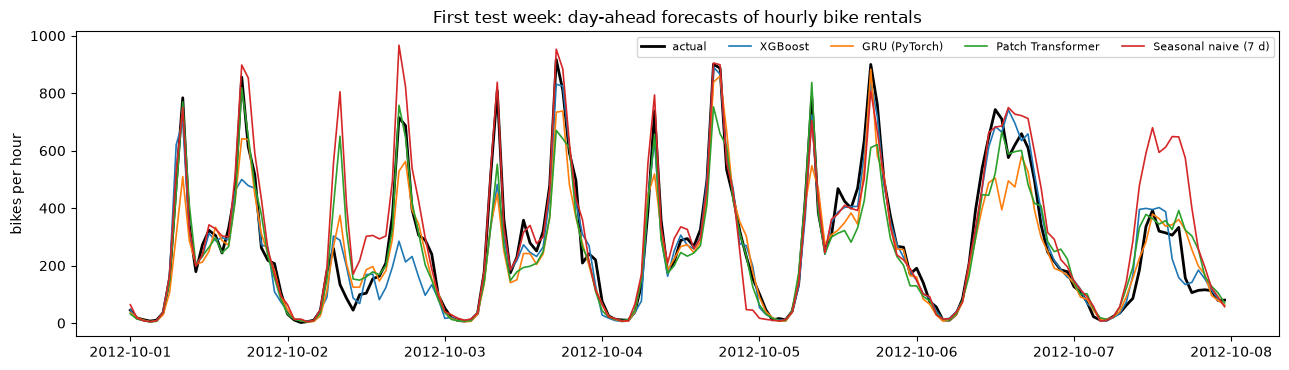

In [7]:
table_a = pd.DataFrame(results).T.sort_values("MAE (bikes/h)")
table_a[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]] = table_a[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]].astype(float).round(1)
display(table_a)
week = slice(0, 24 * 7)
idx = bike.index[bike.index >= TEST_START][week]
plt.figure(figsize=(13, 3.8))
plt.plot(idx, y_true[week], color="black", lw=2, label="actual")
for name in ["XGBoost", "GRU (PyTorch)", "Patch Transformer", "Seasonal naive (7 d)"]:
    plt.plot(idx, forecasts[name][week], lw=1.2, label=name)
plt.legend(ncol=5, fontsize=8); plt.title("First test week: day-ahead forecasts of hourly bike rentals"); plt.ylabel("bikes per hour")
plt.tight_layout(); plt.show()

### Reading the bike results

**The neural networks lose here, and that is the honest result.** Seasonal naive makes 75.9 bikes per hour of error (MAE) and XGBoost 44.6 (RMSE 71.0). The three networks land in between: the GRU at 49.4, the patch Transformer at 50.9 and the LSTM at 51.3, about 11 to 15% worse than XGBoost, after tens of seconds of training against one second. They do cut the naive error by a third, so they are real models: from a raw week of history they rediscovered most of what the lag features gave XGBoost for free. They are also close to each other, and with a single training run each (one random seed) the differences between the three of them are within what a different seed could change, so do not read a ranking into them.

Why trees win this problem: the information sits in a few strong features known at forecast time (hour, working day, weather) and in sharp if-then interactions ("rush hour, but only on working days"), which are exactly what trees are made of; there is little data (about 3,600 training windows from 21 months of one city) and mixed inputs that need no scaling. This agrees with the finding of [Grinsztajn et al. (2022)](https://arxiv.org/abs/2207.08815) that tree ensembles remain hard to beat on tabular data of moderate size.

**Versus the Python 1001 module:** its GRU got 46.4 and its LSTM (Keras) 50.0, with XGBoost at the same 44.6. Here the GRU is 3 points worse because it sees fewer training windows (every fourth hour instead of every third, 3,618 against 4,824) to keep the CPU time down; the LSTM and Transformer are within a point or so of theirs. The conclusion is unchanged: XGBoost first, networks a little behind.

## 5. Problem 2: river flow driven by rain

The flow at a river gauge depends on the rain that fell on the catchment (the land that drains to the gauge), but not in a simple way: rain first fills the soil, and only a wet soil produces runoff; water then reaches the river over hours to days along slow and fast paths, with a delay and a shape specific to each catchment. The soil moisture is a **hidden state** that is never measured directly.

We simulate **24 catchments** with a standard conceptual model (a soil store with a non-linear runoff threshold, fast and slow reservoirs, and a catchment-specific routing delay), each with its own unknown parameters, so the true behaviour is known and no licensing issue arises. On large real datasets of this kind (for example CAMELS, [Addor et al., 2017](https://doi.org/10.5194/hess-21-5293-2017), 671 US catchments) LSTMs have outperformed conceptual hydrology models ([Kratzert et al., 2018](https://doi.org/10.5194/hess-22-6005-2018)), which is what this example reproduces in miniature. The simulator is the same code and seed as the Python 1001 module.

**Task:** at each forecast origin, given the last 72 hours of rain and flow and the **rain forecast for the next 48 hours**, predict the flow for those 48 hours. One model for all catchments, without telling it which catchment it is looking at: it has to recognise the catchment's behaviour from the history.

simulated 24 catchments x 17,520 hours in 1 s


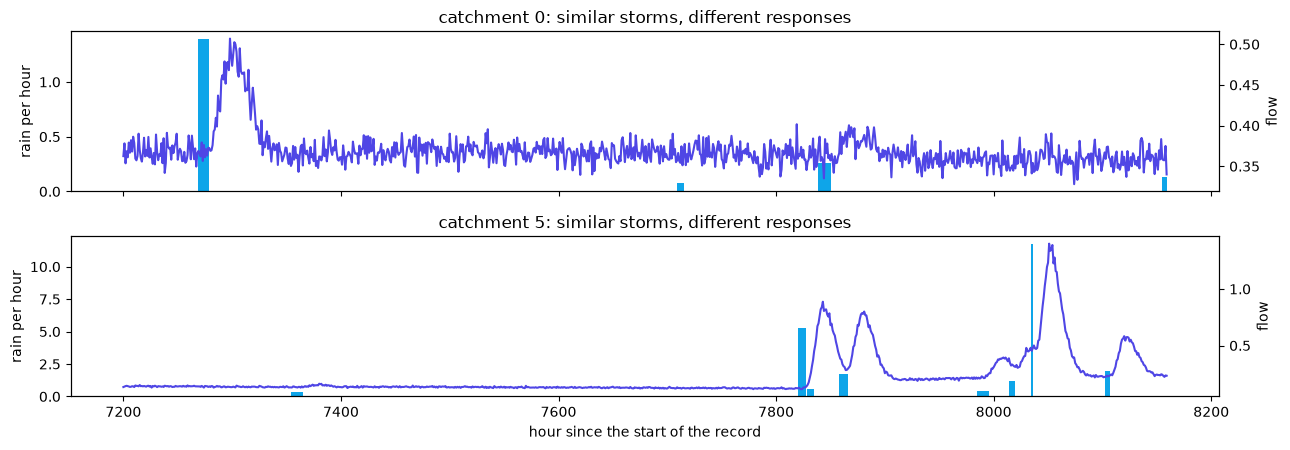

In [8]:
rng = np.random.default_rng(0)
HOURS = 24 * 365 * 2                                  # two years per catchment: year 1 to train, year 2 to test

def simulate_catchment(p, rng):
    t = np.arange(HOURS)
    season = 1 + 0.6 * np.sin(2 * np.pi * t / (24 * 365))
    rain = np.zeros(HOURS)
    for s in np.where(rng.random(HOURS) < 0.015 * season)[0]:          # storms: random starts, more in winter
        dur = rng.integers(2, 14)
        rain[s:s + dur] += rng.gamma(1.4, 7) / dur
    S, fast, slow, q = p["Smax"] * 0.4, 0.0, 0.0, np.zeros(HOURS)
    pet = 0.06 * (1 + 0.8 * np.sin(2 * np.pi * (t - 24 * 80) / (24 * 365)))   # evaporation, higher in summer
    for i in range(HOURS):
        runoff = rain[i] * (S / p["Smax"]) ** p["b"]                    # wet soil -> more of the rain runs off
        S = max(0.0, min(p["Smax"], S + rain[i] - runoff) - pet[i] * S / p["Smax"])
        fast += runoff; slow += 0.004 * S                               # fast surface path, slow groundwater path
        out = p["kf"] * fast + p["ks"] * slow
        fast -= p["kf"] * fast; slow -= p["ks"] * slow
        q[i] = out
    k = np.arange(48)
    uh = k ** (p["shape"] - 1) * np.exp(-k / p["scale"]); uh /= uh.sum()   # routing delay, unique per catchment
    flow = np.convolve(q, uh)[:HOURS]
    return rain, flow * (1 + 0.03 * rng.standard_normal(HOURS))       # 3% measurement noise

t0 = time.perf_counter()
catchments = []
for c in range(24):
    p = dict(Smax=rng.uniform(40, 220), b=rng.uniform(1.5, 4.5), kf=rng.uniform(0.1, 0.4),
             ks=rng.uniform(0.004, 0.02), shape=rng.uniform(1.5, 6), scale=rng.uniform(1.5, 5))
    catchments.append(simulate_catchment(p, rng))
print(f"simulated {len(catchments)} catchments x {HOURS:,} hours in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
for ax, c in zip(axes, [0, 5]):
    rain, flow = catchments[c]
    sl = slice(24 * 300, 24 * 340)
    ax.bar(np.arange(sl.start, sl.stop), rain[sl], color="#0ea5e9", width=1, label="rain")
    ax2 = ax.twinx(); ax2.plot(np.arange(sl.start, sl.stop), flow[sl], color="#4f46e5", label="river flow")
    ax.set_ylabel("rain per hour"); ax2.set_ylabel("flow"); ax.set_title(f"catchment {c}: similar storms, different responses")
axes[1].set_xlabel("hour since the start of the record")
plt.tight_layout(); plt.show()

The size of the response depends on how wet the soil already was, and the delay and shape of the flood wave depend on the catchment. Three kinds of window are built: training (year 1 without its last month), validation (that last month, for early stopping) and test (one forecast a day in year 2, 8,712 forecasts). To keep CPU time down, training windows start every 32 hours here (the Python 1001 module uses every 16), so the models see about half as many training examples as there; this is the main reason some numbers below differ from that module's.

**Baselines.** Persistence (repeat the last flow) is the floor. XGBoost gets the best features we can give it: the recent flow and rain, totals over the window, and the forecast rain for each of the next 48 hours with its running total, with the lead time as a feature. It is lighter than in the Python module (200 trees instead of 500) for the same CPU reason.

In [9]:
import xgboost as xgb
L2, H2 = 72, 48
def windows(rain, flow, start, end, stride):
    X, R, Y = [], [], []
    for o in range(max(start, L2), end - H2, stride):
        X.append(np.stack([rain[o - L2:o], flow[o - L2:o]], 1)); R.append(rain[o:o + H2]); Y.append(flow[o:o + H2])
    return np.array(X, np.float32), np.array(R, np.float32), np.array(Y, np.float32)

YEAR = 24 * 365
tr = [windows(r, f, 0, YEAR - 24 * 30, 32) for r, f in catchments]             # training, last month held out
va = [windows(r, f, YEAR - 24 * 30, YEAR, 24) for r, f in catchments]          # validation for early stopping
te = [windows(r, f, YEAR, HOURS, 24) for r, f in catchments]                    # one forecast a day in year 2
stack = lambda parts, k: np.concatenate([p[k] for p in parts])
Xtr2, Rtr2, Ytr2 = (stack(tr, k) for k in range(3))
Xva2, Rva2, Yva2 = (stack(va, k) for k in range(3))
Xte2, Rte2, Yte2 = (stack(te, k) for k in range(3))
print("train", Xtr2.shape, "validation", Xva2.shape, "test", Xte2.shape)

# a thin, evenly spaced subset of test windows (one forecast every 32 days per catchment): the foundation model
# of section 7 is slow on a CPU, so every model is also scored on this subset for a like-for-like comparison
SUB = np.concatenate([off + np.arange(0, len(t[0]), 32) for off, t in zip(np.cumsum([0] + [len(t[0]) for t in te[:-1]]), te)])
print("subset for the foundation model:", len(SUB), "of", len(Yte2), "test windows")

results2, preds2 = {}, {}
top = Yte2 > np.quantile(Yte2, 0.95)
def score2(name, pred, seconds, params=None, idx=None):
    # pred is for all test windows, or only for the subset when idx is given
    full = idx is None
    sub = pred[SUB] if full else pred
    ref = Yte2[SUB]
    results2[name] = {"MAE (all)": float(np.mean(np.abs(pred - Yte2))) if full else np.nan,
                      "MAE (subset)": float(np.mean(np.abs(sub - ref))),
                      "RMSE (subset)": float(np.sqrt(np.mean((sub - ref) ** 2))),
                      "top-5% flows MAE (subset)": float(np.mean(np.abs(sub - ref)[top[SUB]])),
                      "seconds": seconds, "parameters": params}
    preds2[name] = pred
    r = results2[name]
    print(f"{name:<30} MAE all {r['MAE (all)']:.4f}  subset {r['MAE (subset)']:.4f}  RMSE {r['RMSE (subset)']:.4f}  top-5% {r['top-5% flows MAE (subset)']:.4f}  ({seconds:.0f} s)")

score2("Persistence (last flow)", np.repeat(Xte2[:, -1:, 1], H2, 1), 0, 0)

def table(X, R):
    rain, flow = X[:, :, 0], X[:, :, 1]
    base = np.concatenate([flow[:, -24:], rain[:, -24:], rain.sum(1, keepdims=True), flow.mean(1, keepdims=True),
                           flow.max(1, keepdims=True), R, np.cumsum(R, 1)], 1)
    lead = np.tile(np.arange(H2), len(base))[:, None]
    return np.concatenate([np.repeat(base, H2, 0), lead], 1).astype(np.float32)

t0 = time.perf_counter()
gbm2 = xgb.XGBRegressor(n_estimators=200, max_depth=7, learning_rate=0.1, subsample=0.5, colsample_bytree=0.8,
                        tree_method="hist", n_jobs=2, random_state=0)
gbm2.fit(table(Xtr2, Rtr2), Ytr2.reshape(-1))
score2("XGBoost (engineered features)", gbm2.predict(table(Xte2, Rte2)).reshape(-1, H2), time.perf_counter() - t0, "200 trees")

train (5952, 72, 2) validation (672, 72, 2) test (8712, 72, 2)
subset for the foundation model: 288 of 8712 test windows
Persistence (last flow)        MAE all 0.1186  subset 0.1187  RMSE 0.2419  top-5% 0.5549  (0 s)


XGBoost (engineered features)  MAE all 0.0607  subset 0.0569  RMSE 0.1138  top-5% 0.2655  (58 s)


## 6. Neural networks on problem 2: encoder-decoder GRU and LSTM, and a patch Transformer

An **encoder** reads the 72 past hours of rain and flow; its final hidden state is the network's own estimate of the catchment's condition (how wet, how fast it responds). A **decoder** then walks through the 48 forecast hours, reading the forecast rain one hour at a time and updating that state, the way the water moves through the catchment. No features are engineered. The loss is the MAE, which is robust to the occasional huge flood.

The patch Transformer of section 4 is reused as it is: the 72 past hours are cut into 12 patches of 6 hours, and the 48 forecast rain values go to the head. It has no recurrent state at all, so it is a clean test of whether attention over patches can replace the hidden state.

In [10]:
r_sd, f_sd = Xtr2[:, :, 0].std(), Ytr2.std()
def norm(X, R):
    return np.concatenate([X[:, :, :1] / r_sd, X[:, :, 1:] / f_sd], 2).astype(np.float32), (R / r_sd)[..., None].astype(np.float32)
(Xtr_n, Rtr_n), (Xva_n, Rva_n), (Xte_n, Rte_n) = norm(Xtr2, Rtr2), norm(Xva2, Rva2), norm(Xte2, Rte2)
train2 = (Xtr_n, Rtr_n, (Ytr2 / f_sd).astype(np.float32))
val2 = (Xva_n, Rva_n, (Yva2 / f_sd).astype(np.float32))
test2 = (Xte_n, Rte_n, None)

class Seq2Seq(nn.Module):
    '''Encoder RNN reads the past; its final state initialises a decoder RNN that is fed the forecast rain step by step.'''
    def __init__(self, kind, hidden=48, n_out=1):
        super().__init__()
        cell = nn.GRU if kind == "gru" else nn.LSTM
        self.encoder, self.decoder = cell(2, hidden, batch_first=True), cell(1, hidden, batch_first=True)
        self.out, self.n_out = nn.Linear(hidden, n_out), n_out
    def forward(self, x, r):
        _, state = self.encoder(x)                 # the learned "state of the catchment" (for an LSTM: hidden and cell)
        y, _ = self.decoder(r, state)              # carried forward through the forecast rain
        y = self.out(y)
        return y.squeeze(-1) if self.n_out == 1 else y

l1 = nn.functional.l1_loss
for name, net in [("GRU encoder-decoder", Seq2Seq("gru")), ("LSTM encoder-decoder", Seq2Seq("lstm")),
                  ("Patch Transformer", PatchTransformer(2, 1, L2, H2, patch=6, d=48))]:
    torch.manual_seed(0)
    p, ep, secs = fit(net, train2, val2, test2, loss_fn=l1, epochs=20, lr=2e-3 if "Patch" not in name else 1e-3, patience=4)
    score2(name, p * f_sd, secs, count_params(net)); print(f"   stopped after {ep} epochs")
    if name.startswith("GRU"):
        gru_net = net

GRU encoder-decoder            MAE all 0.0500  subset 0.0454  RMSE 0.1006  top-5% 0.2486  (38 s)
   stopped after 20 epochs


LSTM encoder-decoder           MAE all 0.0545  subset 0.0492  RMSE 0.1085  top-5% 0.2849  (19 s)
   stopped after 20 epochs


Patch Transformer              MAE all 0.0538  subset 0.0491  RMSE 0.1026  top-5% 0.2600  (22 s)
   stopped after 20 epochs


### Reading the river results

**Here the recurrent networks beat XGBoost.** Over all 8,712 test windows the MAE is 0.0500 for the encoder-decoder GRU, 0.0538 for the patch Transformer, 0.0545 for the LSTM and 0.0607 for XGBoost with engineered features, against 0.1186 for persistence (repeating the last flow). The GRU is therefore 18% better than XGBoost on average error and 6% better on the top 5% of flows (0.2486 against 0.2655, on the 288-window subset of section 5), the floods a warning service exists for; the LSTM is better than XGBoost on average but worse on those floods (0.2849). The patch Transformer, with no recurrent state, is level with the LSTM on average error (slightly ahead) and also beats XGBoost on the floods (0.2600). The reason the recurrent models are ahead is the one from the problem description: the final encoder state is a learned estimate of how wet the catchment is, and the decoder applies the same update every hour with the same weights; a tree has to learn separate splits for every combination of rain hour and lead time.

**These gaps are smaller than in the Python 1001 module** (there the GRU cut the error by about 40% against XGBoost: 0.0342 against 0.0561). Two things changed on purpose to save CPU time. The networks here train on half as many windows (every 32 hours instead of 16), with a smaller hidden size (48 instead of 64) and at most 20 epochs, and all three networks stopped because they hit that 20-epoch cap, not because validation loss had stopped improving, so they are probably under-trained. Meanwhile XGBoost uses 200 trees instead of 500 and still got slightly worse than there (0.0607 against 0.0561). The ranking at the ends (GRU first, XGBoost behind all three networks) is the same; the size of the gap is not, and it is the part you should not trust. Exercise 3 and a longer training run are the way to check.

## 7. Zero-shot: a pre-trained foundation model (TimesFM 3)

A **foundation model** for time series is a Transformer pre-trained on a very large collection of real and synthetic series from many domains ([TimesFM, Das et al., 2024](https://arxiv.org/abs/2310.10688); [code](https://github.com/google-research/timesfm); [TimesFM 3 model card](https://huggingface.co/google/timesfm-3.0-pytorch)). It is never trained on our data: give it a stretch of history and it returns a forecast, the way a language model continues a text. It can also read **covariates**, extra input series such as the weather, but there is no training step.

**Check the licence before using it in a project.** The TimesFM code is Apache-2.0, but the TimesFM 3 weights are published under Google's *timesfm-non-commercial-license-v1.0*: fine for learning and research, not for self-hosted commercial or production use. TimesFM 2.5 has Apache-2.0 weights. It is installed from GitHub at a pinned commit (see `requirements.txt`; the PyPI release is older) and the weights (1.3 GB) download from Hugging Face the first time the model loads.

**Cost, and what is reduced here.** Inference on a CPU is slow compared with everything else in this notebook (about half a second per forecast, against milliseconds for the small networks), so the comparison is run on reduced sets, and said so in the tables:
- problem 1: all 92 test days, with covariates (weather and calendar), and 512 hours (three weeks) of history, where the Python 1001 module gave it 2,048 hours;
- problem 2: the evenly spaced subset of test windows defined in section 5, with the rain as covariate and 336 hours (two weeks) of flow history, where the Python module used 512 hours and all 8,712 windows. Every other model is also scored on this subset in the tables below.

Forecasts are cached in `~/.cache/neural-networks-1001/` on first run (the model is deterministic), so running the notebook again does not repeat this computation; delete the folder to recompute.

In [11]:
CACHE = os.path.expanduser("~/.cache/neural-networks-1001"); os.makedirs(CACHE, exist_ok=True)
_model = {}
def tfm_forecast(key, contexts, horizon, covariates):
    '''Zero-shot forecasts with TimesFM 3, cached on disk. Returns (median forecast, quantile forecasts, seconds).'''
    path = f"{CACHE}/{key}.npz"
    if os.path.exists(path):
        z = np.load(path); print(f"{key}: loaded from cache (originally {float(z['seconds']):.0f} s)")
        return z["mean"], z["q"], float(z["seconds"])
    if "m" not in _model:
        from timesfm3 import TimesFM3Forecaster
        _model["m"] = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device="cpu")
    t0 = time.perf_counter()
    out = list(_model["m"].predict_batch(contexts, horizon=horizon, past_future_covariates=covariates, return_quantiles=True))
    secs = time.perf_counter() - t0
    mean, q = np.stack([f.forecast for f in out]), np.stack([f.quantiles for f in out])
    np.savez(path, mean=mean, q=q, seconds=secs)
    return mean, q, secs

# problem 1: every midnight of the test period, 512 hours of history, weather + calendar covariates
CTX1 = 512
COV = ["temp", "humidity", "windspeed", "workingday", "holiday"]
y_all, cov_all = bike["y"].to_numpy(), bike[COV].to_numpy().T
origins = [bike.index.get_loc(d) for d in test_days]
m1, q1, secs1 = tfm_forecast(f"bike_ctx{CTX1}_v1", [y_all[o - CTX1:o] for o in origins], 24,
                             [cov_all[:, o - CTX1:o + 24] for o in origins])
assert np.allclose(m1, q1[:, :, 4], atol=1e-3)               # the point forecast is the median (5th of 9 deciles)
score("TimesFM 3 (zero-shot)", m1.reshape(-1), secs1, "pre-trained, 0 trained")

# problem 2: the subset of test windows, 336 hours of flow, rain as covariate over history and forecast
CTX2 = 336
ctx2, cov2 = [], []
flat = [(c, o) for c, (rain, flow) in enumerate(catchments) for o in range(YEAR, HOURS - H2, 24)]
for i in SUB:
    c, o = flat[i]; rain, flow = catchments[c]
    ctx2.append(flow[o - CTX2:o]); cov2.append(rain[None, o - CTX2:o + H2])
assert np.allclose([catchments[flat[i][0]][1][flat[i][1]:flat[i][1] + H2] for i in SUB], Yte2[SUB])   # same windows as the test set
m2, q2, secs2 = tfm_forecast(f"river_ctx{CTX2}_sub{len(SUB)}_v1", ctx2, H2, cov2)
score2("TimesFM 3 (zero-shot)", m2, secs2, "pre-trained, 0 trained", idx=SUB)

TimesFM 3 (zero-shot)      MAE   46.9   RMSE   78.8   (43 s)


TimesFM 3 (zero-shot)          MAE all nan  subset 0.0414  RMSE 0.0929  top-5% 0.2004  (44 s)


### Results of both problems

Problem 1: hourly bike demand, 92 test days (lower is better)


,MAE (bikes/h),RMSE (bikes/h),seconds,parameters
XGBoost,44.6,71.0,1.3,800 trees
TimesFM 3 (zero-shot),46.9,78.8,42.7,"pre-trained, 0 trained"
GRU (PyTorch),49.4,79.2,24.1,53656.0
Patch Transformer,50.9,81.8,7.4,171032.0
LSTM (PyTorch),51.3,79.0,17.4,58520.0
Seasonal naive (7 d),75.9,129.8,0.0,0.0


Problem 2: river flow, 'subset' = 288 evenly spaced test windows, 'all' = 8,712 (lower is better)


,MAE (all),MAE (subset),RMSE (subset),top-5% flows MAE (subset),seconds,parameters
TimesFM 3 (zero-shot),NaN,0.0414,0.0929,0.2004,44.0,"pre-trained, 0 trained"
GRU encoder-decoder,0.0500,0.0454,0.1006,0.2486,38.0,14881.0
Patch Transformer,0.0538,0.0491,0.1026,0.2600,22.0,131520.0
LSTM encoder-decoder,0.0545,0.0492,0.1085,0.2849,19.0,19825.0
XGBoost (engineered features),0.0607,0.0569,0.1138,0.2655,58.0,200 trees
Persistence (last flow),0.1186,0.1187,0.2419,0.5549,0.0,0.0


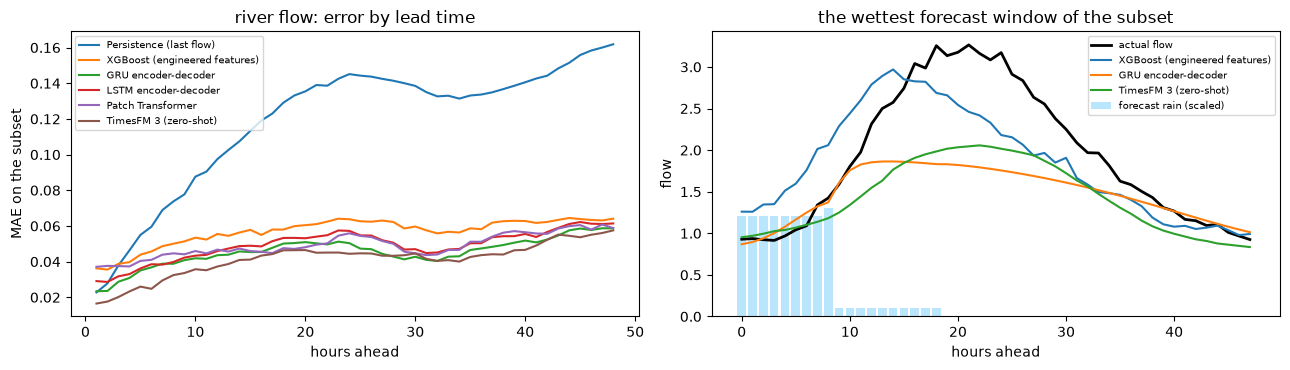

In [12]:
t1 = pd.DataFrame(results).T.sort_values("MAE (bikes/h)")
t1[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]] = t1[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]].astype(float).round(1)
print("Problem 1: hourly bike demand, 92 test days (lower is better)")
display(t1)
t2 = pd.DataFrame(results2).T.sort_values("MAE (subset)")
t2[["MAE (all)", "MAE (subset)", "RMSE (subset)", "top-5% flows MAE (subset)"]] = t2[["MAE (all)", "MAE (subset)", "RMSE (subset)", "top-5% flows MAE (subset)"]].astype(float).round(4)
t2["seconds"] = t2["seconds"].astype(float).round(0)
print(f"Problem 2: river flow, 'subset' = {len(SUB)} evenly spaced test windows, 'all' = {len(Yte2):,} (lower is better)")
display(t2)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in preds2:
    if name == "TimesFM 3 (zero-shot)":
        err = np.mean(np.abs(preds2[name] - Yte2[SUB]), 0)
    else:
        err = np.mean(np.abs(preds2[name][SUB] - Yte2[SUB]), 0)
    ax[0].plot(range(1, H2 + 1), err, label=name)
ax[0].set_xlabel("hours ahead"); ax[0].set_ylabel("MAE on the subset"); ax[0].set_title("river flow: error by lead time"); ax[0].legend(fontsize=7)
i = int(SUB[np.argmax(Rte2[SUB].sum(1))])                         # the subset window with the most rain
j = int(np.where(SUB == i)[0][0])
ax[1].bar(range(H2), Rte2[i] / Rte2[i].max() * Yte2[i].max() * 0.4, color="#bae6fd", label="forecast rain (scaled)")
ax[1].plot(Yte2[i], color="black", lw=2, label="actual flow")
for name in ["XGBoost (engineered features)", "GRU encoder-decoder"]:
    ax[1].plot(preds2[name][i], label=name)
ax[1].plot(preds2["TimesFM 3 (zero-shot)"][j], label="TimesFM 3 (zero-shot)")
ax[1].set_xlabel("hours ahead"); ax[1].set_ylabel("flow"); ax[1].set_title("the wettest forecast window of the subset"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Reading the zero-shot results

**Problem 1 (bike demand): TimesFM 3 is second, close behind XGBoost.** With the weather and calendar as covariates it reaches an MAE of 46.9 bikes per hour (RMSE 78.8), against 44.6 for XGBoost and 49.4 for the best network trained here, without ever seeing this city. That is **worse than the 40.6 the Python 1001 module reports for the same model**, where it came first. The difference is the history it is given: 512 hours (three weeks) here against 2,048 hours (twelve weeks) there. We did not test it, but the likely reason is that the longer window shows it more of the weekly and seasonal pattern and the 2012 growth; it is also a reminder that a foundation model's accuracy depends on how much context you can afford to give it. The cost is high: about 43 seconds of CPU for 92 forecasts, against about 1 second for XGBoost.

**Problem 2 (river flow): TimesFM 3 is first on the subset.** On the 288 evenly spaced test windows its MAE is 0.0414 against 0.0454 for the GRU, 0.0491 for the Transformer, 0.0492 for the LSTM and 0.0569 for XGBoost, and on the top 5% of flows it is clearly ahead (0.2004 against 0.2486 for the GRU). It was never trained on these catchments, but it is also not like for like: it read 336 hours of flow history where the networks read 72, and it ran in about 44 seconds for only 288 forecasts (roughly 0.15 seconds each, against milliseconds for the GRU). Note the subset is a sample: it is a little easier than the full test year for every trained model (the GRU scores 0.0454 on it and 0.0500 on all windows), the order of the trained models is the same on the subset as on all windows, and 288 windows is too few to claim small differences. In the Python 1001 module, with all 8,712 windows, the foundation model's lead was smaller (0.0325 against 0.0342), because there the GRU was better trained.

The pattern across both problems is the same as in that module: a pre-trained model with the known drivers as covariates is a strong first baseline that costs no training but costs inference time, and it does not always beat the specialist (it did not on bike demand).

## 8. Probabilistic forecasting: predicting a band, not a line

A point forecast hides how sure the model is, and for a flood warning or a stock of spare bikes the uncertainty is the point. The standard neural recipe is **quantile regression** ([Koenker and Bassett, 1978](https://doi.org/10.2307/1913643)): instead of one output, the network outputs several quantiles (the 10th, 50th and 90th percentiles, the "q10, q50, q90"), each trained with the **pinball loss**. For a quantile level $\tau$ (tau, between 0 and 1) and an error $e = y - \hat y_\tau$ (actual minus forecast):

$$ \rho_\tau(e) = \max(\tau\, e,\ (\tau - 1)\, e) $$

For $\tau = 0.9$ an under-forecast ($e > 0$) costs 0.9 per unit and an over-forecast only 0.1, so the network learns to put the 90th-percentile forecast above the actual value about nine times in ten. For $\tau = 0.5$ the loss is half the absolute error, so the median is the MAE forecast we trained above. Two checks matter: **coverage** (the actual value falls inside the q10-q90 band about 80% of the time if the quantiles are calibrated) and the **pinball loss** averaged over the three levels (sharper bands with the same coverage score lower).

We train the river encoder-decoder GRU with three outputs per hour. TimesFM returns nine deciles per hour for free; we use its 10th, 50th and 90th. The network's quantiles are sorted at prediction time so that they cannot cross.

quantile GRU: 20 epochs, 39 s


,coverage of the q10-q90 band (target 0.80),mean band width,pinball loss
"GRU, quantile loss (all test windows)",0.8273,0.1445,0.0152
"GRU, quantile loss (subset)",0.8367,0.1380,0.0135
"TimesFM 3, zero-shot (subset)",0.8181,0.1582,0.0136


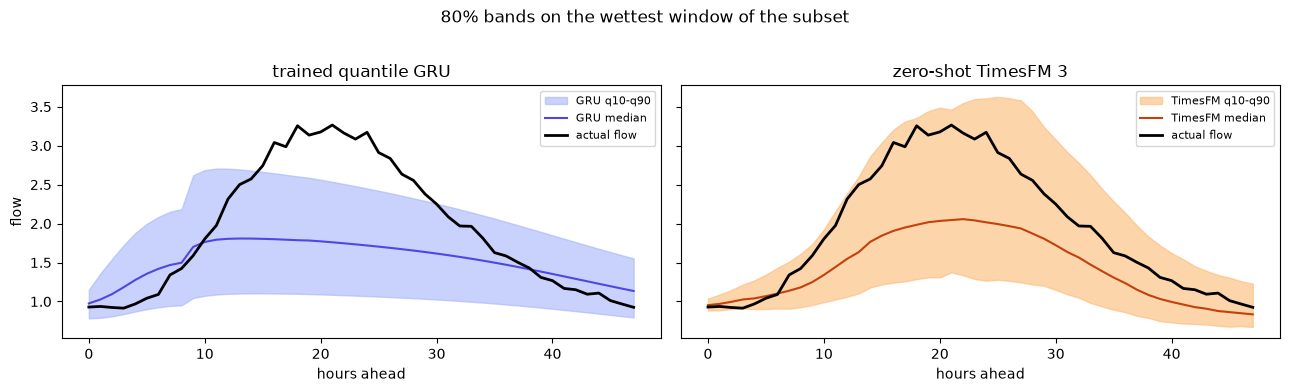

In [13]:
QS = torch.tensor([0.1, 0.5, 0.9])
def pinball(pred, y):
    e = y.unsqueeze(-1) - pred                          # (batch, hours, 3): one error per quantile level
    return torch.maximum(QS * e, (QS - 1) * e).mean()

torch.manual_seed(0)
qnet = Seq2Seq("gru", n_out=3)
pq, ep, secs = fit(qnet, train2, val2, test2, loss_fn=pinball, epochs=20, lr=2e-3, patience=4)
pq = np.sort(pq * f_sd, axis=-1)                         # (windows, hours, 3), quantiles in order
print(f"quantile GRU: {ep} epochs, {secs:.0f} s")

def band_scores(q, y):
    cover = float(np.mean((y >= q[..., 0]) & (y <= q[..., 2])))
    width = float(np.mean(q[..., 2] - q[..., 0]))
    e = y[..., None] - q
    loss = float(np.mean(np.maximum(np.array([0.1, 0.5, 0.9]) * e, (np.array([0.1, 0.5, 0.9]) - 1) * e)))
    return cover, width, loss

q_tfm = q2[:, :, [0, 4, 8]]                              # TimesFM's 10th, 50th and 90th percentiles
rows = {"GRU, quantile loss (all test windows)": band_scores(pq, Yte2),
        "GRU, quantile loss (subset)": band_scores(pq[SUB], Yte2[SUB]),
        "TimesFM 3, zero-shot (subset)": band_scores(q_tfm, Yte2[SUB])}
prob = pd.DataFrame(rows, index=["coverage of the q10-q90 band (target 0.80)", "mean band width", "pinball loss"]).T.round(4)
display(prob)

sub_pos = int(np.where(SUB == i)[0][0])
hrs = np.arange(H2)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
ax[0].fill_between(hrs, pq[i][:, 0], pq[i][:, 2], color="#a5b4fc", alpha=.6, label="GRU q10-q90")
ax[0].plot(hrs, pq[i][:, 1], color="#4f46e5", label="GRU median")
ax[1].fill_between(hrs, q_tfm[sub_pos][:, 0], q_tfm[sub_pos][:, 2], color="#fdba74", alpha=.6, label="TimesFM q10-q90")
ax[1].plot(hrs, q_tfm[sub_pos][:, 1], color="#c2410c", label="TimesFM median")
for a, t in zip(ax, ["trained quantile GRU", "zero-shot TimesFM 3"]):
    a.plot(hrs, Yte2[i], color="black", lw=2, label="actual flow"); a.set_xlabel("hours ahead"); a.set_title(t); a.legend(fontsize=8)
ax[0].set_ylabel("flow")
plt.suptitle("80% bands on the wettest window of the subset", y=1.02)
plt.tight_layout(); plt.show()

### Reading the probabilistic results

**Both bands are close to calibrated.** The q10-q90 band should contain the actual flow 80% of the time. The quantile GRU achieves 82.7% over all 8,712 test windows (83.7% on the subset) and the zero-shot TimesFM 3 achieves 81.8% on the subset, so neither is badly over- or under-confident. The GRU's band is a little narrower (mean width 0.138 against 0.158 on the subset), and its pinball loss is 0.0135 against 0.0136: a **tie** for practical purposes on 288 windows, which means the uncertainty of the pre-trained model, with no training, is as good as that of a network trained for this task. Sharper bands with the same coverage are the goal; the plots show both bands around the actual flow for the wettest window.

Caveats: this is one training run on simulated catchments whose noise is a clean 3%, so real data will have worse calibration (rain forecasts are not perfect, and here the rain forecast is the true rain, which makes both models look better than they would operationally). A quantile network can also be badly calibrated outside the period it was trained on; checking coverage on recent data is a standard monitoring step.

## 9. A decision guide: when is each neural model worth its cost?

Costs are measured above on one laptop CPU (2 threads); accuracy is the MAE relative to the strongest non-neural baseline, XGBoost, on the same test windows (below 1.0 means better than XGBoost).

In [14]:
rel1 = {n: r["MAE (bikes/h)"] / results["XGBoost"]["MAE (bikes/h)"] for n, r in results.items()}
rel2 = {n: r["MAE (subset)"] / results2["XGBoost (engineered features)"]["MAE (subset)"] for n, r in results2.items()}
canon = {"GRU (PyTorch)": "GRU", "GRU encoder-decoder": "GRU", "LSTM (PyTorch)": "LSTM", "LSTM encoder-decoder": "LSTM",
         "Patch Transformer": "Patch Transformer", "TimesFM 3 (zero-shot)": "TimesFM 3 zero-shot", "XGBoost": "XGBoost",
         "XGBoost (engineered features)": "XGBoost", "Seasonal naive (7 d)": "Seasonal naive / persistence",
         "Persistence (last flow)": "Seasonal naive / persistence"}
rows = {}
for n, v in rel1.items():
    rows.setdefault(canon[n], {})["bike MAE / XGBoost"] = round(v, 2); rows[canon[n]]["bike seconds"] = round(float(results[n]["seconds"]))
for n, v in rel2.items():
    rows.setdefault(canon[n], {})["river MAE / XGBoost"] = round(v, 2); rows[canon[n]]["river seconds"] = round(float(results2[n]["seconds"]))
    rows[canon[n]]["river parameters"] = results2[n]["parameters"]
order = ["Seasonal naive / persistence", "XGBoost", "GRU", "LSTM", "Patch Transformer", "TimesFM 3 zero-shot"]
display(pd.DataFrame(rows).T.loc[order])

,bike MAE / XGBoost,bike seconds,river MAE / XGBoost,river seconds,river parameters
Seasonal naive / persistence,1.7,0.0,2.09,0.0,0.0
XGBoost,1.0,1,1.0,58,200 trees
GRU,1.11,24.0,0.8,38.0,14881.0
LSTM,1.15,17.0,0.87,19.0,19825.0
Patch Transformer,1.14,7.0,0.86,22.0,131520.0
TimesFM 3 zero-shot,1.05,43,0.73,44,"pre-trained, 0 trained"


### Reading the table

The accuracy and cost columns come from the runs above, on a shared laptop CPU: the seconds fluctuate by a factor of two or three with what else the machine is doing (the same GRU took noticeably different times in different runs), so read orders of magnitude, not exact values. The TimesFM seconds are for the reduced sets of section 7 (92 forecasts for bike, 288 for river).

**When is each neural model worth its cost?**

| Situation | Choice | Why |
|---|---|---|
| a table of strong known drivers (calendar, weather, prices), one or a few series, moderate data | **XGBoost with lags first**, seasonal naive as the floor | the networks were 11 to 15% worse here, 5 to 20 times slower to train, and trees explain themselves |
| hidden state, long memory, smooth delayed responses to inputs (hydrology, battery or thermal systems), many related series | **GRU or LSTM encoder-decoder** (GRU first: fewer parameters, similar accuracy) | 18% better than XGBoost on average here, and 6% on the floods; the state is learned instead of engineered |
| very long inputs, many series, a lot of data | **patch Transformer** | patches make attention affordable; on our tiny data it was never the best (it needs data to pay for its 130,000 to 170,000 parameters); [Zeng et al. (2023)](https://arxiv.org/abs/2205.13504) show that on some benchmarks even a linear layer can match elaborate Transformers, so always include simple baselines |
| little data, no time to train, or you need a strong first baseline | **a zero-shot foundation model**, with the known drivers as covariates | no training; first on river flow, second on bike demand; costs under a second of CPU per forecast and a non-commercial licence for the TimesFM 3 weights |
| you need to act on risk (flood warnings, safety stock) | train with **quantile loss**, or use the model's quantiles, and check coverage | the band was well calibrated, point forecasts hide the risk |

**Costs to count before choosing a neural model:** training time (and retraining as data drifts), inference cost at your volume (the foundation model is hundreds to a thousand times slower per forecast than the small networks), parameters and memory, and the work of tuning and monitoring. The decisive rule is the one from module 03: the simplest model that is clearly better on a time-split test wins, and "clearly" means beating seasonal naive and XGBoost by a margin larger than the seed-to-seed noise.

## Key takeaways

* Forecast **directly** (all lead times at once from rolling origins), split by **time**, and always compare with **seasonal naive and gradient boosting** before trusting a network.
* On **tabular problems with strong known drivers** (bike demand) the GRU, LSTM and patch Transformer were 11 to 15% worse than XGBoost (49.4 to 51.3 against 44.6 bikes per hour) and much slower to train.
* On a problem with a **hidden state and delayed responses** (river flow), the encoder-decoder GRU was 18% better than XGBoost on average (0.0500 against 0.0607) and 6% better on the top 5% of flows; the patch Transformer and the LSTM were between the two. The gap was smaller than in the Python 1001 module because of the cheaper training used here.
* A **pre-trained foundation model** (TimesFM 3), used zero-shot with covariates, was second on bike demand (46.9) and first on river flow (0.0414 against 0.0454 for the GRU on the 288-window subset), at the price of under a second of CPU per forecast and a non-commercial licence. Its accuracy depends on the history length it is given (46.9 here with 512 hours, 40.6 with 2,048 in the Python module).
* **Quantile (pinball) loss** gives a network a calibrated band: the 80% band covered 82.7% of the flows, and the zero-shot model's band was as good (81.8%, same pinball loss within noise).
* These are CPU toys: one seed, small networks, one simulated dataset and one real city. Trust the reasons and the ranking pattern, not the third digit.

## Exercises

1. In problem 1, drop the weather columns from the XGBoost features and from the networks' inputs. Which model suffers most, and does a network close the gap?
2. In problem 2, add an *antecedent precipitation index* (an exponentially weighted sum of past rain, the hydrologist's proxy for soil moisture) to the XGBoost table. How much of the gap to the GRU does one well-chosen feature close?
3. Train the river GRU on only 6 catchments and test on the other 18. Does it still beat XGBoost on catchments it has never seen? What does that say about "global" models?
4. Train the quantile GRU for the bike problem (24 hours, three quantiles). Is its band calibrated? Why might a band trained on 21 months of data be too narrow on a new quarter?
5. Give TimesFM 3 only the same 72 hours of history as the GRU (and then 1,000 hours). How does the error change, and what does it say about the cost-accuracy trade-off?
6. Replace the patch size 24 in the bike Transformer by 6 and by 168 (one token for the whole week). Which is better, and why does the patch size act as an inductive bias?

## References

- Fanaee-T, H. and Gama, J. (2013). Event labeling combining ensemble detectors and background knowledge. *Progress in Artificial Intelligence*. [doi:10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3). Dataset: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) (CC BY 4.0), [OpenML 42712](https://www.openml.org/d/42712).
- Chen, T. and Guestrin, C. (2016). XGBoost: a scalable tree boosting system. [arXiv:1603.02754](https://arxiv.org/abs/1603.02754).
- Cho, K. et al. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation (the GRU). [arXiv:1406.1078](https://arxiv.org/abs/1406.1078).
- Hochreiter, S. and Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*. [doi:10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735).
- Nie, Y. et al. (2023). A time series is worth 64 words: long-term forecasting with Transformers (PatchTST). ICLR. [arXiv:2211.14730](https://arxiv.org/abs/2211.14730).
- Zeng, A. et al. (2023). Are Transformers effective for time series forecasting? AAAI. [arXiv:2205.13504](https://arxiv.org/abs/2205.13504).
- Das, A. et al. (2024). A decoder-only foundation model for time-series forecasting (TimesFM). ICML. [arXiv:2310.10688](https://arxiv.org/abs/2310.10688). Code: [github.com/google-research/timesfm](https://github.com/google-research/timesfm); weights: [google/timesfm-3.0-pytorch](https://huggingface.co/google/timesfm-3.0-pytorch) (non-commercial licence).
- Koenker, R. and Bassett, G. (1978). Regression quantiles. *Econometrica*. [doi:10.2307/1913643](https://doi.org/10.2307/1913643).
- Kratzert, F. et al. (2018). Rainfall-runoff modelling using long short-term memory networks. *Hydrology and Earth System Sciences*. [doi:10.5194/hess-22-6005-2018](https://doi.org/10.5194/hess-22-6005-2018).
- Addor, N. et al. (2017). The CAMELS data set: catchment attributes and meteorology for large-sample studies. *Hydrology and Earth System Sciences*. [doi:10.5194/hess-21-5293-2017](https://doi.org/10.5194/hess-21-5293-2017).
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? NeurIPS. [arXiv:2207.08815](https://arxiv.org/abs/2207.08815).